# Experimento 13 — Forma recente e Top 3 por RMSE

Comparação controlada: as 22 features do Exp. 12 vs. as mesmas 22 + quatro diferenças
dos últimos 10 jogos. Reutilizamos exclusivamente o catálogo e os pesos salvos do Exp. 12.
Não há nova descoberta AutoML nem geração de configurações TabPFN.

Cada configuração é reajustada independentemente com Season < 2023, < 2024 e < 2025.
M/W separados, cinco folds internos agrupados por temporada, seed 42.
Somente **RMSE ponderado** seleciona o Top 3; Logistic Brier é diagnóstico.
Os anos usados na seleção não constituem teste independente. [Detalhes](../../docs/exp13.md).


In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

atual = Path.cwd().resolve()
raiz = next(p for p in [atual, *atual.parents] if (p / 'raw_data').is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src import exp11 as comum, exp12 as anterior, exp13 as exp
from src.automl_h2o import inicializar_h2o
from src.recent_features import ESTATISTICAS_RECENTES

SEED = 42
ANOS = [2023, 2024, 2025]
N_FOLDS = 5
FEATURES_CONTROLE = list(exp.FEATURES_CONTROLE)
FEATURES = list(exp.FEATURES)
NOVAS = [n + 'Diff' for n in ESTATISTICAS_RECENTES]
assert len(FEATURES_CONTROLE) == 22 and len(FEATURES) == 26
ORIGEM = raiz / 'checkpoints' / 'exp12'
CHECKPOINTS = raiz / 'checkpoints' / 'exp13'
ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA = 4 * 3600  # None percorre todo o catálogo.
COMPLETAR_CONTROLE_FALTANTE = False
REPETIR_FALHAS = False
N_THREADS = 2
MAX_MEM_SIZE = '4G'
display(FEATURES, comum.versoes())


['SeedDif',
 'WinRateDiff',
 'AvgPointsForDiff',
 'AvgPointsAgainstDiff',
 'OppWinRateDiff',
 'FGPercentageDiff',
 'ThreePointPercentageDiff',
 'FTPercentageDiff',
 'AssistsPerGameDiff',
 'OffensiveReboundsPerGameDiff',
 'DefensiveReboundsPerGameDiff',
 'TurnoversPerGameDiff',
 'StealsPerGameDiff',
 'BlocksPerGameDiff',
 'OffensiveRatingDiff',
 'DefensiveRatingDiff',
 'NetRatingDiff',
 'PossessionsPerGameDiff',
 'EffectiveFGPercentageDiff',
 'TurnoverRateDiff',
 'OffensiveReboundRateDiff',
 'FreeThrowRateDiff',
 'RecentWinRate10Diff',
 'RecentAvgMargin10Diff',
 'RecentAvgPointsFor10Diff',
 'RecentAvgPointsAgainst10Diff']

{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Catálogo e similaridade de origem

As receitas de stacking e suas dependências permanecem fixas. Os ensembles serão
reconstruídos com previsões OOF anteriores a cada corte; podem não ser binariamente
idênticos aos originais do AutoML. Ausência ou ambiguidade nos arquivos de origem
interrompe a leitura, sem substituição do catálogo. Os pesos dos perfis originais
de similaridade são lidos diretamente, sem recalculá-los com as novas features.


In [2]:
manifesto = exp.carregar_catalogo(ORIGEM)
catalogo = manifesto['candidatos']
REFERENCIAS = manifesto['referencias']
tabela_catalogo = pd.DataFrame(catalogo)
tabela_catalogo['StackedEnsemble'] = tabela_catalogo.Familia.str.startswith('StackedEnsemble_')
display(tabela_catalogo.groupby(['Categoria', 'Abordagem', 'Familia']).size().rename('Candidatos'))
display(tabela_catalogo[['Candidato', 'Categoria', 'Abordagem', 'Familia', 'Parametros']])
display(REFERENCIAS)
print('Total:', len(catalogo), '| Cortes externos planejados (26 features):', 3 * len(catalogo))
comum.salvar_json(CHECKPOINTS / 'catalogo.json',
    {**manifesto, 'referencias': REFERENCIAS.to_dict('records')})


Categoria  Abordagem  Familia                     
M          h2o        StackedEnsemble_AllModels         1
                      StackedEnsemble_BestOfFamily      1
                      drf                               2
                      gbm                             105
                      glm                               1
           tabpfn     V3_5                             50
                      V3_5_FAST                        50
W          h2o        StackedEnsemble_AllModels         1
                      StackedEnsemble_BestOfFamily      1
                      drf                               2
                      gbm                             105
                      glm                               1
           tabpfn     V3_5                             50
                      V3_5_FAST                        50
Name: Candidatos, dtype: int64

,Candidato,Categoria,Abordagem,Familia,Parametros
0,M_h2o_0c6c991e59254b1a,M,h2o,glm,"{'seed': 42, 'ignore_const_cols': True, 'score..."
1,M_h2o_ab487be0e86b80ec,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in..."
2,M_h2o_5eb6e9d905cc8d68,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in..."
3,M_h2o_5909c78566707e22,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in..."
4,M_h2o_0ec9f93125b10153,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in..."
...,...,...,...,...,...
415,W_tabpfn12_dca0267e0adceea1,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando..."
416,W_tabpfn12_9b930594f0e2a382,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando..."
417,W_tabpfn12_6955b0f184868879,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando..."
418,W_tabpfn12_40450405c352c05b,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 64, 'rando..."


,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


Total: 420 | Cortes externos planejados (26 features): 1260


## Dados e forma recente

RegularSeasonCompactResults, duas participações W/L por partida. Janela independente
por equipe/temporada, ordenada por DayNum e OpponentID. Menos de dez jogos: usar os
disponíveis e registrar a quantidade. Somente jogos anteriores ao NCAA; 2026: DayNum < 134.
RecentAvgMargin10Diff é redundante com a diferença entre as duas médias de pontos,
mas permanece no conjunto solicitado.


,Categoria,JogosTreinoHistorico,PrimeiroAno,UltimoAno,FontesFeatures,Limite2026,SemSobreposicaoNCAA,JogosDetalhados2026,UltimoDayNum2026
0,M,1449,2003,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5647,132
1,W,961,2010,2025,RegularSeasonCompactResults + RegularSeasonDet...,134,True,5479,132


M


,RecentGames10,RecentFirstDayNum10,RecentLastDayNum10
count,7993.000000,7993.000000,7993.000000
mean,9.998999,93.752283,126.399600
std,0.068947,6.304696,4.094139
min,4.000000,4.000000,46.000000
25%,10.000000,89.000000,124.000000
50%,10.000000,94.000000,127.000000
75%,10.000000,96.000000,129.000000
max,10.000000,111.000000,132.000000


,RecentWinRate10Diff,RecentAvgMargin10Diff,RecentAvgPointsFor10Diff,RecentAvgPointsAgainst10Diff
count,1449.000000,1449.000000,1449.000000,1449.000000
mean,0.007591,0.272257,0.669427,0.397170
std,0.222425,7.402866,8.132184,8.100868
min,-0.700000,-30.500000,-24.600000,-23.900000
25%,-0.100000,-4.600000,-5.000000,-5.100000
50%,0.000000,-0.100000,0.600000,0.300000
75%,0.200000,5.000000,6.300000,5.800000
max,0.600000,29.000000,25.500000,28.800000


,NaN,Inf
SeedDif,0,0
WinRateDiff,0,0
AvgPointsForDiff,0,0
AvgPointsAgainstDiff,0,0
OppWinRateDiff,0,0
FGPercentageDiff,0,0
ThreePointPercentageDiff,0,0
FTPercentageDiff,0,0
AssistsPerGameDiff,0,0
OffensiveReboundsPerGameDiff,0,0


,SeedDif,WinRateDiff,AvgPointsForDiff,AvgPointsAgainstDiff,OppWinRateDiff,FGPercentageDiff,ThreePointPercentageDiff,FTPercentageDiff,AssistsPerGameDiff,OffensiveReboundsPerGameDiff,...,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff,RecentWinRate10Diff,RecentAvgMargin10Diff,RecentAvgPointsFor10Diff,RecentAvgPointsAgainst10Diff,Target
RecentWinRate10Diff,-0.030084,0.578135,0.143473,-0.224705,-0.357367,0.245523,0.151255,0.035246,0.089580,-0.058416,...,-0.028156,0.252022,-0.088780,0.000545,0.023881,1.000000,0.801429,0.318092,-0.413054,0.055511
RecentAvgMargin10Diff,-0.127208,0.601216,0.286657,-0.278653,-0.260126,0.368392,0.206859,0.053937,0.236085,-0.002065,...,0.029711,0.368422,-0.157981,0.076158,-0.000215,0.801429,1.000000,0.459381,-0.452680,0.150287
RecentAvgPointsFor10Diff,-0.144625,0.319432,0.800137,0.540879,-0.024517,0.434569,0.275752,0.143201,0.415309,0.221340,...,0.664419,0.438616,-0.166393,0.150689,0.107921,0.318092,0.459381,1.000000,0.584067,0.113089
RecentAvgPointsAgainst10Diff,-0.028937,-0.228746,0.541273,0.797614,0.213101,0.099599,0.087783,0.094465,0.201172,0.224083,...,0.639836,0.103635,-0.022668,0.081675,0.108534,-0.413054,-0.452680,0.584067,1.000000,-0.023812


W


,RecentGames10,RecentFirstDayNum10,RecentLastDayNum10
count,5615.000000,5615.000000,5615.000000
mean,9.992342,92.481389,125.626714
std,0.200938,6.594519,4.755392
min,2.000000,23.000000,37.000000
25%,10.000000,89.000000,123.000000
50%,10.000000,93.000000,125.000000
75%,10.000000,96.000000,129.000000
max,10.000000,111.000000,132.000000


,RecentWinRate10Diff,RecentAvgMargin10Diff,RecentAvgPointsFor10Diff,RecentAvgPointsAgainst10Diff
count,961.000000,961.000000,961.000000,961.000000
mean,0.018730,2.078668,0.933923,-1.144745
std,0.246608,11.931936,9.912819,9.328126
min,-0.700000,-35.600000,-32.300000,-35.800000
25%,-0.200000,-6.300000,-5.700000,-7.600000
50%,0.000000,1.900000,0.700000,-0.900000
75%,0.200000,10.000000,7.400000,5.200000
max,0.700000,39.500000,28.500000,30.700000


,NaN,Inf
SeedDif,0,0
WinRateDiff,0,0
AvgPointsForDiff,0,0
AvgPointsAgainstDiff,0,0
OppWinRateDiff,0,0
FGPercentageDiff,0,0
ThreePointPercentageDiff,0,0
FTPercentageDiff,0,0
AssistsPerGameDiff,0,0
OffensiveReboundsPerGameDiff,0,0


,SeedDif,WinRateDiff,AvgPointsForDiff,AvgPointsAgainstDiff,OppWinRateDiff,FGPercentageDiff,ThreePointPercentageDiff,FTPercentageDiff,AssistsPerGameDiff,OffensiveReboundsPerGameDiff,...,PossessionsPerGameDiff,EffectiveFGPercentageDiff,TurnoverRateDiff,OffensiveReboundRateDiff,FreeThrowRateDiff,RecentWinRate10Diff,RecentAvgMargin10Diff,RecentAvgPointsFor10Diff,RecentAvgPointsAgainst10Diff,Target
RecentWinRate10Diff,-0.014660,0.679541,0.288496,-0.358373,-0.295363,0.341933,0.268253,0.161767,0.320667,0.015586,...,-0.100984,0.365314,-0.272945,0.145051,-0.024603,1.000000,0.828100,0.488785,-0.539829,0.104505
RecentAvgMargin10Diff,-0.140950,0.702729,0.476051,-0.441347,-0.147790,0.545783,0.373796,0.213200,0.514670,0.021347,...,-0.047528,0.560423,-0.407423,0.201769,-0.139268,0.828100,1.000000,0.649401,-0.589030,0.305453
RecentAvgPointsFor10Diff,-0.312037,0.536522,0.829570,0.224202,0.101616,0.626324,0.460084,0.351897,0.623056,0.124558,...,0.504770,0.642542,-0.423605,0.180484,-0.004094,0.488785,0.649401,1.000000,0.232009,0.361425
RecentAvgPointsAgainst10Diff,-0.151301,-0.328734,0.272635,0.802798,0.297029,-0.032548,0.010788,0.101243,0.003777,0.105060,...,0.597204,-0.034039,0.070993,-0.066294,0.173793,-0.539829,-0.589030,0.232009,1.000000,-0.006636


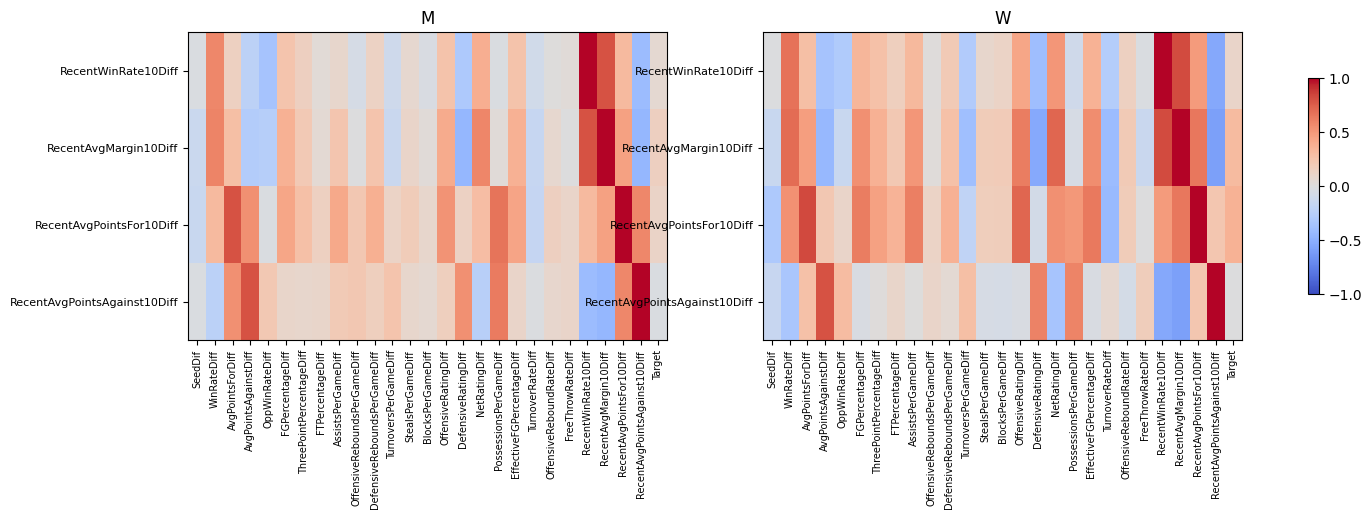

In [3]:
preparacao = exp.preparar_dados(raiz / 'raw_data')
jogos, controle = preparacao['jogos'], preparacao['controle']
confrontos, sample = preparacao['confrontos'], preparacao['sample']
display(preparacao['auditoria'])
for cat, tabela in jogos.items():
    print(cat)
    display(preparacao['recentes'][cat][['RecentGames10', 'RecentFirstDayNum10', 'RecentLastDayNum10']].describe())
    display(tabela[NOVAS].describe())
    display(pd.DataFrame({'NaN': tabela[FEATURES].isna().sum(),
        'Inf': np.isinf(tabela[FEATURES].to_numpy()).sum(axis=0)}, index=FEATURES))
    assert tabela.TeamA.lt(tabela.TeamB).all()
    np.testing.assert_allclose(tabela.Target, tabela.ScoreA - tabela.ScoreB)
    np.testing.assert_allclose(tabela.RecentAvgMargin10Diff,
        tabela.RecentAvgPointsFor10Diff - tabela.RecentAvgPointsAgainst10Diff, atol=1e-12)
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    pd.testing.assert_frame_equal(tabela[controle[cat].columns], controle[cat])
    limites = preparacao['recentes'][cat].Season.map(preparacao['limites'][cat])
    assert preparacao['recentes'][cat].RecentLastDayNum10.lt(limites).all()
    assert preparacao['recentes'][cat].query('Season == 2026').RecentLastDayNum10.lt(134).all()
    display(tabela[[*FEATURES, 'Target']].corr().loc[NOVAS])

fig, axes = plt.subplots(1, 2, figsize=(17, 4))
for ax, (cat, tabela) in zip(axes, jogos.items()):
    matriz = tabela[[*FEATURES, 'Target']].corr().loc[NOVAS]
    im = ax.imshow(matriz, vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
    ax.set(xticks=range(len(matriz.columns)), yticks=range(4),
        xticklabels=matriz.columns, yticklabels=NOVAS, title=cat)
    ax.tick_params(axis='x', labelrotation=90, labelsize=7)
    ax.tick_params(axis='y', labelsize=8)
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=.7)
plt.show()


## Controle de 22 features

Copiar apenas checkpoints compatíveis em dados, configurações, versões e protocolo.
O Exp. 12 é somente leitura. Candidatos ausentes ou com falha aparecem na cobertura;
não serão substituídos. Por padrão, o controle não realiza novos ajustes.
Para completá-lo, habilitar COMPLETAR_CONTROLE_FALTANTE: os novos resultados serão
salvos exclusivamente no Exp. 13.


In [4]:
reuso = exp.reutilizar_controle(controle, catalogo, pasta_exp12=ORIGEM,
    destino=CHECKPOINTS / 'controle' / 'avaliacao')
display(reuso.groupby(['Categoria', 'Abordagem', 'Status']).size().rename('Cortes'))
avaliacao_controle = exp.ler_controle(controle, catalogo, pasta=CHECKPOINTS / 'controle' / 'avaliacao')
print('Cortes do controle ausentes ou não equivalentes:', len(avaliacao_controle['pendentes']))
comum.salvar_json(CHECKPOINTS / 'controle' / 'reuso.json', reuso.to_dict('records'))


Categoria  Abordagem  Status        
M          h2o        reutilizado_ok    330
           tabpfn     reutilizado_ok    300
W          h2o        reutilizado_ok    330
           tabpfn     reutilizado_ok    300
Name: Cortes, dtype: int64

Cortes do controle ausentes ou não equivalentes: 0


## Ambiente e avaliação das 26 features

TabPFN V3.5/3.5-Fast em CUDA, sequencialmente. Autenticação em `.env.tabpfn`, como no
Exp. 12. O filtro do aviso obsoleto é aplicado somente no contexto TabPFN; avisos
de CUDA, memória e problemas numéricos permanecem visíveis.

O orçamento TabPFN é cumulativo por categoria e verificado entre candidatos completos
(três cortes). Pode ultrapassar o limite durante um candidato. Para continuar além
do orçamento anterior, aumente-o ou use None e execute novamente: checkpoints válidos
serão reutilizados. H2O e os ajustes finais não entram nesse limite.


In [5]:
from h2o.exceptions import H2ODependencyWarning
warnings.filterwarnings('ignore', category=H2ODependencyWarning,
    message=r'Converting H2O frame to pandas dataframe using single-thread\.', module=r'h2o\.frame')
comum.configurar_avisos_h2o()
ambiente_tabpfn = comum.detectar_tabpfn(exigir_gpu=True)
comum.carregar_token_tabpfn(raiz / '.env.tabpfn')
display(comum.validar_acesso_tabpfn())
ambiente_h2o = inicializar_h2o(nthreads=N_THREADS, max_mem_size=MAX_MEM_SIZE)
display(ambiente_tabpfn, ambiente_h2o)
comum.salvar_json(CHECKPOINTS / 'ambiente.json', {'tabpfn': ambiente_tabpfn, 'h2o': ambiente_h2o})

if COMPLETAR_CONTROLE_FALTANTE:
    avaliacao_controle = anterior.avaliar_banco(controle, catalogo, features=FEATURES_CONTROLE,
        pasta=CHECKPOINTS / 'controle' / 'avaliacao', n_folds=N_FOLDS, seed=SEED,
        orcamento_tabpfn_por_categoria=ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA,
        repetir_falhas=REPETIR_FALHAS)


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

Checking whether there is an H2O instance running at http://127.0.0.1:54329. connected.


H2O_cluster_uptime:,1 hour 55 mins
H2O_cluster_timezone:,America/Sao_Paulo
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 23 days
H2O_cluster_name:,H2O_from_python_davis_9ofekd
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.501 Gb
H2O_cluster_total_cores:,12
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+
Cannot build an XGBoost model - no backend found.


{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

{'h2o_version': '3.46.0.12',
 'cluster_version': '3.46.0.12',
 'xgboost_disponivel': False,
 'exclude_algos': ['DeepLearning', 'XGBoost'],
 'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias habilitadas.'}

In [6]:
avaliacao_nova = exp.avaliar_novo(jogos, catalogo, pasta=CHECKPOINTS / 'recente' / 'avaliacao',
    orcamento_tabpfn=ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA, repetir_falhas=REPETIR_FALHAS)
assert manifesto['assinaturas'] == {c['Candidato']: exp.assinatura_candidato(c) for c in catalogo}
print('Candidatos pendentes:', avaliacao_nova['pendentes'])
display(pd.DataFrame([{k: r.get(k) for k in ['Categoria', 'Abordagem', 'Familia', 'Candidato', 'Season',
    'status', 'RMSE', 'LB', 'SegundosTreino', 'SegundosInferencia', 'recursos', 'erro']}
    for r in avaliacao_nova['avaliacoes']]))


H2O/M/2023: 110 candidatos registrados.
H2O/M/2024: 110 candidatos registrados.
H2O/M/2025: 110 candidatos registrados.
TabPFN/M: M_tabpfn12_2973465e4981a4f7 registrado.
TabPFN/M: M_tabpfn12_53e56db25f2544e6 registrado.
TabPFN/M: M_tabpfn12_33d31c0be877a927 registrado.
TabPFN/M: M_tabpfn12_34cc6a16be684582 registrado.
TabPFN/M: M_tabpfn12_2c5a2f66d71abdc7 registrado.
TabPFN/M: M_tabpfn12_95beaf425161d405 registrado.
TabPFN/M: M_tabpfn12_2ccb9a971c426ab1 registrado.
TabPFN/M: M_tabpfn12_8766363716aa1313 registrado.
TabPFN/M: M_tabpfn12_7c8a0580fab71131 registrado.
TabPFN/M: M_tabpfn12_90729dade6f72bfe registrado.
TabPFN/M: M_tabpfn12_9d0ebfa70f4dee59 registrado.
TabPFN/M: M_tabpfn12_8e7fba8b158096f7 registrado.
TabPFN/M: M_tabpfn12_5a771e6f02aacf60 registrado.
TabPFN/M: M_tabpfn12_31dc1e9d61399623 registrado.
TabPFN/M: M_tabpfn12_d1eec64c5c3daa7d registrado.
TabPFN/M: M_tabpfn12_193a5f1fc6b02274 registrado.
TabPFN/M: M_tabpfn12_66abb88e8a794c6e registrado.
TabPFN/M: M_tabpfn12_25bcb8c52

,Categoria,Abordagem,Familia,Candidato,Season,status,RMSE,LB,SegundosTreino,SegundosInferencia,recursos,erro
0,M,h2o,glm,M_h2o_0c6c991e59254b1a,2023,ok,12.368552,0.090654,0.227981,0.262159,"{'rss_pico_mb': 925.84375, 'jvm_heap_observado...",None
1,M,h2o,gbm,M_h2o_ab487be0e86b80ec,2023,ok,12.144625,0.086714,0.634985,0.249459,"{'rss_pico_mb': 925.11328125, 'jvm_heap_observ...",None
2,M,h2o,gbm,M_h2o_5eb6e9d905cc8d68,2023,ok,12.243835,0.086332,0.425868,0.239083,"{'rss_pico_mb': 925.484375, 'jvm_heap_observad...",None
3,M,h2o,gbm,M_h2o_5909c78566707e22,2023,ok,12.575994,0.098338,0.420787,0.241932,"{'rss_pico_mb': 925.12890625, 'jvm_heap_observ...",None
4,M,h2o,gbm,M_h2o_0ec9f93125b10153,2023,ok,12.191401,0.084246,0.421478,0.238992,"{'rss_pico_mb': 925.0546875, 'jvm_heap_observa...",None
...,...,...,...,...,...,...,...,...,...,...,...,...
1255,W,tabpfn,V3_5,W_tabpfn12_40450405c352c05b,2024,ok,10.410069,0.043000,0.515582,5.061632,"{'rss_pico_mb': 3500.22265625, 'cuda_pico_mb':...",None
1256,W,tabpfn,V3_5,W_tabpfn12_40450405c352c05b,2025,ok,14.372565,0.045410,0.556889,5.229115,"{'rss_pico_mb': 3495.3125, 'cuda_pico_mb': 524...",None
1257,W,tabpfn,V3_5,W_tabpfn12_bbf163bacb28bfc4,2023,ok,12.301586,0.067085,0.635520,4.850157,"{'rss_pico_mb': 3497.47265625, 'cuda_pico_mb':...",None
1258,W,tabpfn,V3_5,W_tabpfn12_bbf163bacb28bfc4,2024,ok,10.396576,0.042097,0.500846,5.086945,"{'rss_pico_mb': 3476.06640625, 'cuda_pico_mb':...",None


## Scores históricos e seleção

Score = soma de Peso(ano) × RMSE(ano), usando os pesos salvos acima.
Apenas candidatos com os três cortes válidos concorrem. Empates: ID do candidato.
O Top 3 é separado por M/W e H2O/TabPFN; LB não muda essa ordem.


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,RMSE_media
0,M,h2o,M_h2o_00767ac1ffc6b6aa,12.602678,12.371552,13.520103,11.919556,0.078447,0.089327,0.081917,0.067186,12.603737
1,M,h2o,M_h2o_02910426eda382fe,12.535825,12.027920,13.579027,11.940016,0.073992,0.081015,0.080943,0.062337,12.515654
2,M,h2o,M_h2o_0509cc915a9aed9f,12.676756,12.839123,13.412427,11.872241,0.081687,0.099317,0.080720,0.069571,12.707931
3,M,h2o,M_h2o_09af85b4d9867b49,12.295607,11.868682,13.274402,11.699943,0.073366,0.081971,0.078431,0.062300,12.281009
4,M,h2o,M_h2o_09ccc9842c545c1b,12.786167,13.236764,13.776452,11.531886,0.085174,0.108147,0.089917,0.063796,12.848368
...,...,...,...,...,...,...,...,...,...,...,...,...
415,W,tabpfn,W_tabpfn12_e5ca5d3fef7485fb,12.397297,12.291647,10.314284,14.413796,0.050283,0.067408,0.043174,0.044254,12.339909
416,W,tabpfn,W_tabpfn12_e6097820cde29070,12.497608,12.355408,10.277299,14.668866,0.050666,0.066735,0.042258,0.046626,12.433858
417,W,tabpfn,W_tabpfn12_f19209e33d0dd91e,12.473767,12.337566,10.282101,14.613942,0.050182,0.066633,0.042067,0.045587,12.411203
418,W,tabpfn,W_tabpfn12_f20bbe99d76118a5,12.373219,12.341563,10.262881,14.360516,0.049900,0.067663,0.042641,0.043540,12.321653


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,Metrica,Posicao,RMSE_media
0,M,h2o,M_h2o_6868c1ea9159ac75,12.101766,11.827025,13.204862,11.278061,0.069981,0.081719,0.075874,0.055830,rmse,1,12.103316
1,M,h2o,M_h2o_c0081fade8d8497a,12.160571,12.433709,12.864047,11.304229,0.073526,0.092575,0.073566,0.059425,rmse,2,12.200661
2,M,h2o,M_h2o_1d1bd60f01ab0f7a,12.162055,11.944327,13.141915,11.410940,0.071516,0.082171,0.075585,0.059861,rmse,3,12.165727
3,M,h2o,M_h2o_4975cc975a607a4d,12.168508,12.124335,13.205235,11.236325,0.071227,0.085889,0.074180,0.057654,rmse,4,12.188632
4,M,h2o,M_stack_AllModels_e131d28a175eeea9,12.178699,12.307233,13.055409,11.267910,0.073721,0.089022,0.076499,0.059838,rmse,5,12.210184
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,W,tabpfn,W_tabpfn12_c8279c54dcb0c2cb,12.493100,12.354556,10.270337,14.663943,0.050670,0.066759,0.042216,0.046658,rmse,96,12.429612
416,W,tabpfn,W_tabpfn12_31dc1e9d61399623,12.494634,12.375161,10.258482,14.663854,0.050761,0.066911,0.042109,0.046888,rmse,97,12.432499
417,W,tabpfn,W_tabpfn12_5cbbc6f4ddfc3e35,12.496957,12.376858,10.271735,14.656470,0.050790,0.066891,0.042389,0.046721,rmse,98,12.435021
418,W,tabpfn,W_tabpfn12_e6097820cde29070,12.497608,12.355408,10.277299,14.668866,0.050666,0.066735,0.042258,0.046626,rmse,99,12.433858


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,RMSE_media
0,M,h2o,M_h2o_00767ac1ffc6b6aa,12.492733,12.496947,13.167276,11.861880,0.076232,0.098212,0.073522,0.062523,12.508701
1,M,h2o,M_h2o_02910426eda382fe,12.504139,12.645492,13.243950,11.711287,0.073823,0.089659,0.073950,0.062011,12.533576
2,M,h2o,M_h2o_0509cc915a9aed9f,12.442498,12.419967,13.190867,11.762688,0.076789,0.089046,0.078435,0.066206,12.457841
3,M,h2o,M_h2o_09af85b4d9867b49,12.393035,11.968646,13.177288,11.976543,0.073961,0.083118,0.073481,0.067647,12.374159
4,M,h2o,M_h2o_09ccc9842c545c1b,12.478712,12.671255,13.399832,11.479334,0.079579,0.097419,0.080814,0.065257,12.516807
...,...,...,...,...,...,...,...,...,...,...,...,...
415,W,tabpfn,W_tabpfn12_e5ca5d3fef7485fb,12.392949,12.268342,10.397471,14.341985,0.050832,0.068297,0.043295,0.044951,12.335932
416,W,tabpfn,W_tabpfn12_e6097820cde29070,12.496341,12.333980,10.362910,14.601636,0.051204,0.067735,0.042205,0.047374,12.432842
417,W,tabpfn,W_tabpfn12_f19209e33d0dd91e,12.477723,12.315017,10.366436,14.562663,0.050736,0.067565,0.041951,0.046484,12.414705
418,W,tabpfn,W_tabpfn12_f20bbe99d76118a5,12.397375,12.310365,10.315500,14.399054,0.050737,0.068465,0.042478,0.045333,12.341640


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,Metrica,Posicao,RMSE_media
0,M,h2o,M_h2o_c0081fade8d8497a,12.147848,12.007144,12.989678,11.468314,0.071771,0.083823,0.074958,0.059907,rmse,1,12.155045
1,M,h2o,M_h2o_50723b006219492c,12.152744,11.635181,13.224816,11.537199,0.070308,0.078364,0.074161,0.060775,rmse,2,12.132399
2,M,h2o,M_stack_AllModels_e131d28a175eeea9,12.182464,12.309229,13.165312,11.174207,0.073620,0.089698,0.077451,0.058183,rmse,3,12.216249
3,M,h2o,M_stack_BestOfFamily_3c8d1fae695eb07b,12.197707,12.379906,13.174080,11.154547,0.073974,0.090931,0.077590,0.058088,rmse,4,12.236178
4,M,h2o,M_h2o_aad146d974c1cdd1,12.200871,11.815099,13.498577,11.278037,0.071222,0.081863,0.079093,0.056040,rmse,5,12.197238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415,W,tabpfn,W_tabpfn12_31dc1e9d61399623,12.491621,12.346491,10.319456,14.620240,0.051225,0.067755,0.042169,0.047447,rmse,96,12.428729
416,W,tabpfn,W_tabpfn12_e6097820cde29070,12.496341,12.333980,10.362910,14.601636,0.051204,0.067735,0.042205,0.047374,rmse,97,12.432842
417,W,tabpfn,W_tabpfn12_5cbbc6f4ddfc3e35,12.498805,12.367208,10.329371,14.614889,0.051319,0.067990,0.042235,0.047464,rmse,98,12.437156
418,W,tabpfn,W_tabpfn12_c8279c54dcb0c2cb,12.501335,12.342742,10.364003,14.607478,0.051255,0.067739,0.042284,0.047433,rmse,99,12.438074


,Categoria,Abordagem,Posicao,Candidato,Familia,RMSE_pond,LB_pond,RMSE_media,RMSE_2023,RMSE_2024,RMSE_2025,LB_2023,LB_2024,LB_2025,Parametros
0,M,h2o,1,M_h2o_c0081fade8d8497a,gbm,12.147848,0.071771,12.155045,12.007144,12.989678,11.468314,0.083823,0.074958,0.059907,"{'score_each_iteration': False, 'score_tree_in..."
1,M,h2o,2,M_h2o_50723b006219492c,gbm,12.152744,0.070308,12.132399,11.635181,13.224816,11.537199,0.078364,0.074161,0.060775,"{'score_each_iteration': False, 'score_tree_in..."
2,M,h2o,3,M_stack_AllModels_e131d28a175eeea9,StackedEnsemble_AllModels,12.182464,0.073620,12.216249,12.309229,13.165312,11.174207,0.089698,0.077451,0.058183,"{'Bases': ['M_h2o_0c6c991e59254b1a', 'M_h2o_ab..."
3,W,h2o,1,W_stack_BestOfFamily_dde758149487bfe9,StackedEnsemble_BestOfFamily,12.347934,0.051126,12.294370,12.292422,10.241140,14.349547,0.070608,0.041270,0.045914,"{'Bases': ['W_h2o_2f1eaf68e91ceb17', 'W_h2o_0c..."
4,W,h2o,2,W_stack_AllModels_4e2af0b87a6035bf,StackedEnsemble_AllModels,12.392011,0.051627,12.335107,12.264428,10.412619,14.328274,0.070337,0.043541,0.045337,"{'Bases': ['W_h2o_2f1eaf68e91ceb17', 'W_h2o_0c..."
5,W,h2o,3,W_h2o_2f1eaf68e91ceb17,glm,12.419820,0.051757,12.374636,12.477651,10.247978,14.398279,0.071758,0.041799,0.046256,"{'seed': 42, 'ignore_const_cols': True, 'score..."
6,M,tabpfn,1,M_tabpfn12_2973465e4981a4f7,V3_5_FAST,12.104871,0.073467,12.139198,12.255206,13.022249,11.140139,0.088254,0.077597,0.058705,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
7,M,tabpfn,2,M_tabpfn12_2c5a2f66d71abdc7,V3_5_FAST,12.104900,0.073470,12.139343,12.256059,13.024177,11.137794,0.088283,0.077601,0.058688,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
8,M,tabpfn,3,M_tabpfn12_33d31c0be877a927,V3_5_FAST,12.105004,0.073467,12.139330,12.255725,13.020886,11.141379,0.088249,0.077613,0.058694,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
9,W,tabpfn,1,W_tabpfn12_d1eec64c5c3daa7d,V3_5,12.382968,0.050571,12.328106,12.303340,10.311058,14.369922,0.068667,0.042621,0.044608,"{'version': 'V3_5', 'n_estimators': 4, 'random..."


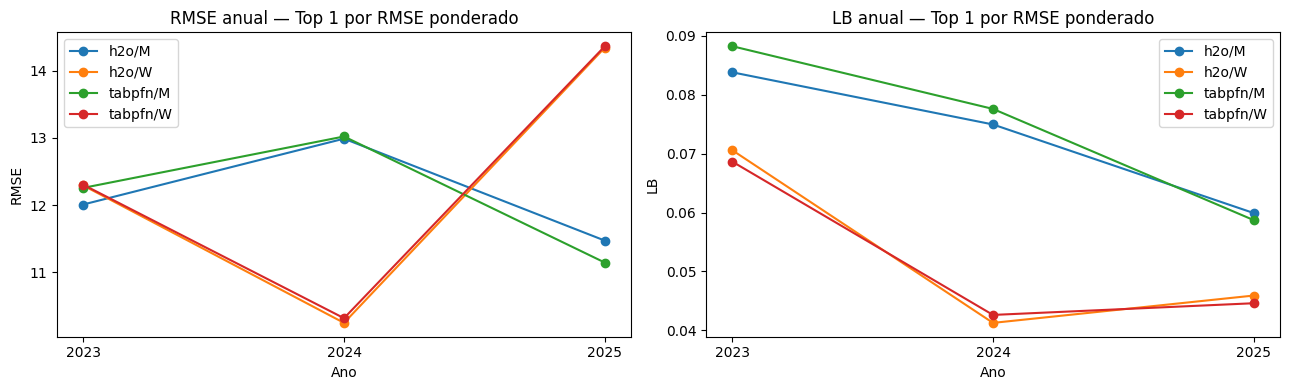

In [7]:
scores26, ranking26 = exp.ranquear(avaliacao_nova['avaliacoes'], REFERENCIAS)
if any(r.get('status') == 'ok' for r in avaliacao_controle['avaliacoes']):
    completos = pd.DataFrame(avaliacao_controle['avaliacoes']).groupby('Candidato').status.agg(
        lambda s: len(s) == 3 and s.eq('ok').all())
    tem_controle_completo = completos.any()
else:
    tem_controle_completo = False
if tem_controle_completo:
    scores22, ranking22 = exp.ranquear(avaliacao_controle['avaliacoes'], REFERENCIAS)
else:
    scores22, ranking22 = scores26.iloc[:0].copy(), ranking26.iloc[:0].copy()
    print('Sem controle completo equivalente: não é possível atribuir diferenças às features.')

for nome, scores, ranking in [('controle22', scores22, ranking22), ('recente26', scores26, ranking26)]:
    display(scores, ranking)
    comum.salvar_json(CHECKPOINTS / (nome + '_rankings.json'),
        {'scores': scores.to_dict('records'), 'ranking': ranking.to_dict('records')})

top3 = ranking26.loc[ranking26.Posicao.le(3)].merge(
    tabela_catalogo[['Candidato', 'Familia', 'Parametros']], on='Candidato', validate='one_to_one')
display(top3[['Categoria', 'Abordagem', 'Posicao', 'Candidato', 'Familia', 'RMSE_pond', 'LB_pond',
    'RMSE_media', 'RMSE_2023', 'RMSE_2024', 'RMSE_2025', 'LB_2023', 'LB_2024', 'LB_2025', 'Parametros']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metrica in zip(axes, ['RMSE', 'LB']):
    for row in top3.loc[top3.Posicao.eq(1)].itertuples():
        ax.plot(ANOS, [getattr(row, f'{metrica}_{a}') for a in ANOS], marker='o',
            label=f'{row.Abordagem}/{row.Categoria}')
    ax.set(title=f'{metrica} anual — Top 1 por RMSE ponderado', xticks=ANOS, xlabel='Ano', ylabel=metrica)
    ax.legend()
plt.tight_layout()
plt.show()


## Comparação pareada com o Exp. 12

Somente os mesmos candidatos completos nas 22 e 26 features. Deltas negativos
indicam melhora. Posições recalculadas no mesmo conjunto pareado. Cobertura parcial
não permite conclusões sobre os candidatos ausentes. As métricas são de validação
usada na seleção, sem interpretação como teste independente.


,Categoria,Abordagem,Catalogo,Completos22,Completos26,ParesCompletos
0,M,h2o,110,110,110,110
1,M,tabpfn,100,100,100,100
2,W,h2o,110,110,110,110
3,W,tabpfn,100,100,100,100


,Categoria,Abordagem,Candidato,RMSE_pond_22,RMSE_2023_22,RMSE_2024_22,RMSE_2025_22,LB_pond_22,LB_2023_22,LB_2024_22,...,LB_2023_26,LB_2024_26,LB_2025_26,RMSE_media_26,Familia,Delta_RMSE_pond,Delta_LB_pond,Delta_RMSE_media,PosicaoPareada_22,PosicaoPareada_26
82,M,h2o,M_h2o_c0081fade8d8497a,12.160571,12.433709,12.864047,11.304229,0.073526,0.092575,0.073566,...,0.083823,0.074958,0.059907,12.155045,gbm,-0.012723,-0.001755,-0.045616,2,1
40,M,h2o,M_h2o_50723b006219492c,12.195147,11.753110,13.345170,11.451294,0.070621,0.078289,0.077709,...,0.078364,0.074161,0.060775,12.132399,gbm,-0.042403,-0.000313,-0.050792,11,2
108,M,h2o,M_stack_AllModels_e131d28a175eeea9,12.178699,12.307233,13.055409,11.267910,0.073721,0.089022,0.076499,...,0.089698,0.077451,0.058183,12.216249,StackedEnsemble_AllModels,0.003765,-0.000102,0.006065,5,3
109,M,h2o,M_stack_BestOfFamily_3c8d1fae695eb07b,12.217236,12.307233,13.152028,11.280848,0.074335,0.089022,0.077992,...,0.090931,0.077590,0.058088,12.236178,StackedEnsemble_BestOfFamily,-0.019528,-0.000361,-0.010525,15,4
77,M,h2o,M_h2o_aad146d974c1cdd1,12.273357,11.892974,13.409138,11.497237,0.071938,0.082714,0.077041,...,0.081863,0.079093,0.056040,12.197238,gbm,-0.072487,-0.000716,-0.069212,23,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
340,W,tabpfn,W_tabpfn12_31dc1e9d61399623,12.494634,12.375161,10.258482,14.663854,0.050761,0.066911,0.042109,...,0.067755,0.042169,0.047447,12.428729,V3_5,-0.003012,0.000464,-0.003770,97,96
416,W,tabpfn,W_tabpfn12_e6097820cde29070,12.497608,12.355408,10.277299,14.668866,0.050666,0.066735,0.042258,...,0.067735,0.042205,0.047374,12.432842,V3_5,-0.001267,0.000539,-0.001016,99,97
356,W,tabpfn,W_tabpfn12_5cbbc6f4ddfc3e35,12.496957,12.376858,10.271735,14.656470,0.050790,0.066891,0.042389,...,0.067990,0.042235,0.047464,12.437156,V3_5,0.001848,0.000529,0.002135,98,98
394,W,tabpfn,W_tabpfn12_c8279c54dcb0c2cb,12.493100,12.354556,10.270337,14.663943,0.050670,0.066759,0.042216,...,0.067739,0.042284,0.047433,12.438074,V3_5,0.008235,0.000585,0.008462,96,99


Candidatos  DeltaRMSE  \
Categoria Abordagem Familia                                               
M         h2o       StackedEnsemble_AllModels              1   0.003765   
                    StackedEnsemble_BestOfFamily           1  -0.019528   
                    drf                                    2  -0.316863   
                    gbm                                  105   0.060887   
                    glm                                    1   0.005575   
          tabpfn    V3_5                                  50  -0.022194   
                    V3_5_FAST                             50  -0.018003   
W         h2o       StackedEnsemble_AllModels              1   0.006932   
                    StackedEnsemble_BestOfFamily           1  -0.045175   
                    drf                                    2  -0.068177   
                    gbm                                  105  -0.043642   
                    glm                                    1   0.026756   
          tabpfn    V3_5                                  50   0.002556   
                    V3_5_FAST                             50   0.034324   

                                                   DeltaLB  MelhoraramRMSE  \
Categoria Abordagem Familia                                                  
M         h2o       StackedEnsemble_AllModels    -0.000102               0   
                    StackedEnsemble_BestOfFamily -0.000361               1   
                    drf                          -0.004709               2   
                    gbm                           0.000483              44   
                    glm                          -0.000118               0   
          tabpfn    V3_5                         -0.000623              40   
                    V3_5_FAST                    -0.000861              47   
W         h2o       StackedEnsemble_AllModels     0.000993               0   
                    StackedEnsemble_BestOfFamily  0.000301               1   
                    drf                           0.000065               2   
                    gbm                           0.000236              55   
                    glm                           0.001026               0   
          tabpfn    V3_5                          0.000526              16   
                    V3_5_FAST                     0.000596               0   

                                                  MelhoraramLB  
Categoria Abordagem Familia                                     
M         h2o       StackedEnsemble_AllModels                1  
                    StackedEnsemble_BestOfFamily             1  
                    drf                                      2  
                    gbm                                     48  
                    glm                                      1  
          tabpfn    V3_5                                    50  
                    V3_5_FAST                               50  
W         h2o       StackedEnsemble_AllModels                0  
                    StackedEnsemble_BestOfFamily             0  
                    drf                                      1  
                    gbm                                     45  
                    glm                                      0  
          tabpfn    V3_5                                     0  
                    V3_5_FAST                                0

,Categoria,Abordagem,Candidato,Familia,PosicaoPareada_22,PosicaoPareada_26,RMSE_pond_22,RMSE_pond_26,Delta_RMSE_pond,LB_pond_22,LB_pond_26,Delta_LB_pond
12,M,h2o,M_h2o_1d1bd60f01ab0f7a,gbm,3,55,12.162055,12.540802,0.378747,0.071516,0.073052,0.001537
40,M,h2o,M_h2o_50723b006219492c,gbm,11,2,12.195147,12.152744,-0.042403,0.070621,0.070308,-0.000313
54,M,h2o,M_h2o_6868c1ea9159ac75,gbm,1,16,12.101766,12.305784,0.204018,0.069981,0.072965,0.002984
82,M,h2o,M_h2o_c0081fade8d8497a,gbm,2,1,12.160571,12.147848,-0.012723,0.073526,0.071771,-0.001755
108,M,h2o,M_stack_AllModels_e131d28a175eeea9,StackedEnsemble_AllModels,5,3,12.178699,12.182464,0.003765,0.073721,0.073620,-0.000102
124,M,tabpfn,M_tabpfn12_2973465e4981a4f7,V3_5_FAST,7,1,12.127361,12.104871,-0.022490,0.074329,0.073467,-0.000862
125,M,tabpfn,M_tabpfn12_2c5a2f66d71abdc7,V3_5_FAST,9,2,12.128032,12.104900,-0.023132,0.074327,0.073470,-0.000857
132,M,tabpfn,M_tabpfn12_33d31c0be877a927,V3_5_FAST,8,3,12.127384,12.105004,-0.022380,0.074335,0.073467,-0.000868
135,M,tabpfn,M_tabpfn12_36abdf9dabab40fa,V3_5_FAST,2,5,12.113659,12.114713,0.001054,0.074154,0.073605,-0.000549
165,M,tabpfn,M_tabpfn12_95d63295f213febc,V3_5_FAST,3,4,12.114223,12.114504,0.000281,0.074155,0.073601,-0.000554


Melhor base vs. stacking, por RMSE — 22 features, candidatos pareados


,Categoria,Tipo,Candidato,RMSE_pond_22,LB_pond_22
54,M,Base,M_h2o_6868c1ea9159ac75,12.101766,0.069981
108,M,Stacking,M_stack_AllModels_e131d28a175eeea9,12.178699,0.073721
318,W,Stacking,W_stack_AllModels_4e2af0b87a6035bf,12.385079,0.050634
233,W,Base,W_h2o_2f1eaf68e91ceb17,12.393064,0.050730


Melhor base vs. stacking, por RMSE — 26 features, candidatos pareados


,Categoria,Tipo,Candidato,RMSE_pond_26,LB_pond_26
82,M,Base,M_h2o_c0081fade8d8497a,12.147848,0.071771
108,M,Stacking,M_stack_AllModels_e131d28a175eeea9,12.182464,0.073620
319,W,Stacking,W_stack_BestOfFamily_dde758149487bfe9,12.347934,0.051126
233,W,Base,W_h2o_2f1eaf68e91ceb17,12.419820,0.051757


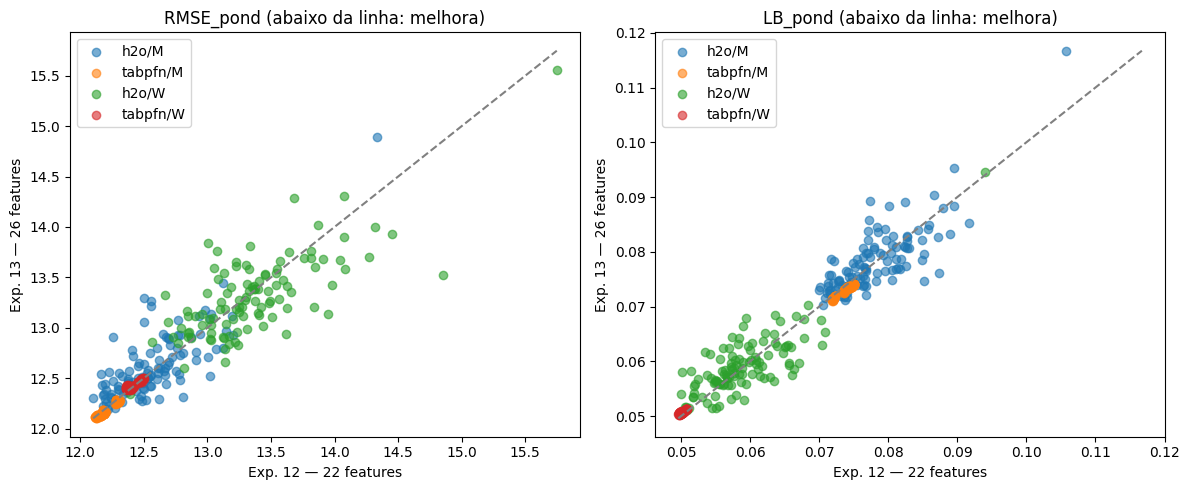

In [8]:
pares, cobertura = exp.comparar_pareado(scores22, scores26, catalogo)
display(cobertura)
display(pares.sort_values(['Categoria', 'Abordagem', 'RMSE_pond_26']))
comum.salvar_json(CHECKPOINTS / 'comparacao.json', {
    'pares': pares.to_dict('records'), 'cobertura': cobertura.to_dict('records')})
if not pares.empty:
    familias = pares.assign(MelhorouRMSE=pares.Delta_RMSE_pond.lt(0),
        MelhorouLB=pares.Delta_LB_pond.lt(0)).groupby(['Categoria', 'Abordagem', 'Familia']).agg(
        Candidatos=('Candidato', 'size'), DeltaRMSE=('Delta_RMSE_pond', 'mean'),
        DeltaLB=('Delta_LB_pond', 'mean'), MelhoraramRMSE=('MelhorouRMSE', 'sum'), MelhoraramLB=('MelhorouLB', 'sum'))
    display(familias)
    display(pares.loc[pares.PosicaoPareada_22.le(3) | pares.PosicaoPareada_26.le(3),
        ['Categoria', 'Abordagem', 'Candidato', 'Familia', 'PosicaoPareada_22', 'PosicaoPareada_26',
         'RMSE_pond_22', 'RMSE_pond_26', 'Delta_RMSE_pond', 'LB_pond_22', 'LB_pond_26', 'Delta_LB_pond']])
    h2o_pares = pares.loc[pares.Abordagem.eq('h2o')].copy()
    h2o_pares['Tipo'] = np.where(h2o_pares.Familia.str.startswith('StackedEnsemble_'), 'Stacking', 'Base')
    for conjunto in ['22', '26']:
        melhores = h2o_pares.sort_values('RMSE_pond_' + conjunto).groupby(['Categoria', 'Tipo']).head(1)
        print('Melhor base vs. stacking, por RMSE —', conjunto, 'features, candidatos pareados')
        display(melhores[['Categoria', 'Tipo', 'Candidato', 'RMSE_pond_' + conjunto, 'LB_pond_' + conjunto]])
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, metrica in zip(axes, ['RMSE_pond', 'LB_pond']):
        for (cat, abordagem), grupo in pares.groupby(['Categoria', 'Abordagem']):
            ax.scatter(grupo[metrica + '_22'], grupo[metrica + '_26'], alpha=.6, label=f'{abordagem}/{cat}')
        minimo = pares[[metrica + '_22', metrica + '_26']].min().min()
        maximo = pares[[metrica + '_22', metrica + '_26']].max().max()
        ax.plot([minimo, maximo], [minimo, maximo], '--', color='gray')
        ax.set(xlabel='Exp. 12 — 22 features', ylabel='Exp. 13 — 26 features', title=metrica + ' (abaixo da linha: melhora)')
        ax.legend()
    plt.tight_layout()
    plt.show()


In [9]:
recursos = pd.DataFrame([{'Conjunto': conjunto, 'Categoria': r['Categoria'], 'Abordagem': r['Abordagem'],
    'Candidato': r['Candidato'], 'Season': r['Season'], 'Status': r['status'],
    'Segundos': r.get('recursos', {}).get('segundos', 0),
    **r.get('recursos', {})} for conjunto, avaliacao in [('22', avaliacao_controle), ('26', avaliacao_nova)]
    for r in avaliacao['avaliacoes']])
display(recursos)
display(recursos.groupby(['Conjunto', 'Categoria', 'Abordagem']).agg(
    Segundos=('Segundos', 'sum'), Cortes=('Status', 'size')))
print('Tempos do controle reutilizado são históricos; não representam custo desta execução.')
comum.salvar_json(CHECKPOINTS / 'recursos.json',
    recursos.astype(object).where(recursos.notna(), None).to_dict('records'))


,Conjunto,Categoria,Abordagem,Candidato,Season,Status,Segundos,rss_pico_mb,jvm_heap_observado_mb,segundos,cuda_pico_mb
0,22,M,h2o,M_h2o_0c6c991e59254b1a,2023,ok,0.501988,3293.050781,102.072982,0.501988,NaN
1,22,M,h2o,M_h2o_0c6c991e59254b1a,2024,ok,0.465288,3295.527344,62.311443,0.465288,NaN
2,22,M,h2o,M_h2o_0c6c991e59254b1a,2025,ok,0.463898,3301.601562,62.772450,0.463898,NaN
3,22,M,h2o,M_h2o_ab487be0e86b80ec,2023,ok,0.684944,3291.250000,102.072982,0.684944,NaN
4,22,M,h2o,M_h2o_ab487be0e86b80ec,2024,ok,0.462208,3295.640625,62.311443,0.462208,NaN
...,...,...,...,...,...,...,...,...,...,...,...
2515,26,W,tabpfn,W_tabpfn12_40450405c352c05b,2024,ok,5.802663,3500.222656,NaN,5.802663,5183.370605
2516,26,W,tabpfn,W_tabpfn12_40450405c352c05b,2025,ok,6.049819,3495.312500,NaN,6.049819,5249.277344
2517,26,W,tabpfn,W_tabpfn12_bbf163bacb28bfc4,2023,ok,5.713885,3497.472656,NaN,5.713885,5196.426758
2518,26,W,tabpfn,W_tabpfn12_bbf163bacb28bfc4,2024,ok,5.800563,3476.066406,NaN,5.800563,5183.370605


Segundos  Cortes
Conjunto Categoria Abordagem                    
22       M         h2o        173.195437     330
                   tabpfn     889.049320     300
         W         h2o        175.826843     330
                   tabpfn     650.617039     300
26       M         h2o        181.492447     330
                   tabpfn     868.758751     300
         W         h2o        181.979564     330
                   tabpfn     622.333202     300

Tempos do controle reutilizado são históricos; não representam custo desta execução.


## Seis submissions de 2026

Top 1 M + Top 1 W, Top 2 M + Top 2 W e Top 3 M + Top 3 W, para cada abordagem.
Somente 26 features, ajuste final com Season < 2026. Margens brutas, fallback zero
para pares sem duas seeds, IDs e ordem idênticos ao sample. Previsões finais
retomáveis; submissions idênticas são identificadas na tabela.


In [10]:
assert len(top3) == 12, 'Faltam três candidatos completos por abordagem/categoria; confira falhas e orçamento.'
submissions = exp.gerar_submissions(jogos, catalogo, ranking26, confrontos, sample,
    pasta=CHECKPOINTS / 'recente' / 'final', destino=raiz / 'submissions')
assert len(submissions['submissions']) == 6
display(pd.DataFrame(submissions['submissions']), pd.DataFrame(submissions['tempos_finais']))
registro = {'features_controle': FEATURES_CONTROLE, 'features': FEATURES, 'anos': ANOS, 'seed': SEED,
    'n_folds': N_FOLDS, 'pesos': REFERENCIAS.to_dict('records'), 'versoes': comum.versoes(),
    'fontes_exp12': manifesto['fontes'], 'assinaturas_candidatos': manifesto['assinaturas'],
    'criterio': 'RMSE ponderado; Logistic Brier somente diagnóstico',
    'orcamento_tabpfn_por_categoria': ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA,
    'completar_controle': COMPLETAR_CONTROLE_FALTANTE,
    'cobertura': cobertura.to_dict('records'), 'submissions': submissions}
comum.salvar_json(CHECKPOINTS / 'registro.json', registro)


,Arquivo,Abordagem,Posicao,ModeloM,ModeloW,Linhas,IdenticaA
0,submission_exp13_h2o_rmse_top1_2026.csv,h2o,1,M_h2o_c0081fade8d8497a,W_stack_BestOfFamily_dde758149487bfe9,132133,None
1,submission_exp13_h2o_rmse_top2_2026.csv,h2o,2,M_h2o_50723b006219492c,W_stack_AllModels_4e2af0b87a6035bf,132133,None
2,submission_exp13_h2o_rmse_top3_2026.csv,h2o,3,M_stack_AllModels_e131d28a175eeea9,W_h2o_2f1eaf68e91ceb17,132133,None
3,submission_exp13_tabpfn_rmse_top1_2026.csv,tabpfn,1,M_tabpfn12_2973465e4981a4f7,W_tabpfn12_d1eec64c5c3daa7d,132133,None
4,submission_exp13_tabpfn_rmse_top2_2026.csv,tabpfn,2,M_tabpfn12_2c5a2f66d71abdc7,W_tabpfn12_66abb88e8a794c6e,132133,None
5,submission_exp13_tabpfn_rmse_top3_2026.csv,tabpfn,3,M_tabpfn12_33d31c0be877a927,W_tabpfn12_a727afef5f6e5059,132133,None


,Candidato,Segundos
0,M_h2o_c0081fade8d8497a,0.718572
1,M_h2o_50723b006219492c,0.713241
2,M_stack_AllModels_e131d28a175eeea9,10.081324
3,M_tabpfn12_2973465e4981a4f7,1.731940
4,M_tabpfn12_2c5a2f66d71abdc7,1.435357
5,M_tabpfn12_33d31c0be877a927,1.413009
6,W_stack_BestOfFamily_dde758149487bfe9,5.054146
7,W_stack_AllModels_4e2af0b87a6035bf,9.163376
8,W_h2o_2f1eaf68e91ceb17,0.307257
9,W_tabpfn12_d1eec64c5c3daa7d,2.404804
